In [ ]:
# import pandas
import pandas as pd # 用於資料處裡、讀取csv檔案、excel檔案等

import numpy as np # 用於數值運算，計算平均、標準差等等

from pathlib import Path # 用於檔案的路徑管理
 
import matplotlib.pyplot as plt # 用於畫圖

import cmcrameri.cm as cmc

# import aaa as bbb, aaa表示module，bbb表示我們為module設定的小名



In [ ]:
cwd = Path.cwd() # cwd = Path.cwd() # 取得目前工作的資料夾

eqe_path=cwd.joinpath("EQE_2026_06_23-13_30.txt") 

JD_path=cwd.joinpath("JD_2026_06_23-13_36.txt")

pv_voltage = cwd.joinpath("pv_triggered.csv")

jv_sweep=cwd.joinpath("jv_sweep.csv")

# 把路徑接起來，並且回傳一個物件，本物件可以連接到我們指定的檔案
# jv_sweep是回傳的物件，他可以連接到我們這個資料家內的jv_sweep.csv檔案



In [14]:

import csv


BLOCK_WIDTH = 6
HEADER_ROW = 4  # row with the data column names
DATA_START = 5


def read_eqe(path):
    """Return (meta, df).

    meta : {sample_name: {key: value}}  numbers -> float, Date -> Timestamp
    df   : index Lambda(nm), columns MultiIndex (sample_name, quantity)
    """
    with open(path, encoding="utf-8", errors="replace", newline="") as f:
        rows = [r for r in csv.reader(f, delimiter="\t") if any(c.strip() for c in r)]

    n_blocks = len(rows[0]) // BLOCK_WIDTH
    meta, frames = {}, {}

    for b in range(n_blocks):
        c0 = b * BLOCK_WIDTH
        block = [r[c0:c0 + BLOCK_WIDTH] for r in rows]

        # metadata: key in col 4, value in col 5 (header "Infomation" has no value)
        m = {"Block": int(block[0][0])}
        for r in block[1:]:
            key, val = r[4].strip(), r[5].strip()
            if key and key != "Infomation":
                m[key] = _convert(key, val)
        # AM1.5G/D/AM0 Jsc are repeated in cols 0-1 of rows 1-3; those are the same values
        name = m.get("Name") or f"block{b + 1}"
        if name in meta:
            raise ValueError(f"duplicate sample name {name!r} (block {b + 1})")

        cols = [c.strip() for c in block[HEADER_ROW][:4]]
        data = pd.DataFrame(
            [[float(x) for x in r[:4]] for r in block[DATA_START:] if r[0].strip()],
            columns=cols,
        ).set_index(cols[0])
        meta[name], frames[name] = m, data

    df = pd.concat(frames, axis=1)
    return meta, df


def _convert(key, val):
    if key == "Date":
        return pd.to_datetime(val, format="%Y-%m-%d_%H-%M-%S")
    if key == "Range (nm)":
        return val  # e.g. "300 - 1100"
    try:
        return float(val)
    except ValueError:
        return val


if __name__ == "__main__":
    meta, df = read_eqe("EQE_2026_06_23-13_30.txt")
    print(meta["G1-3"])
    print(df.shape)
    print(df["G1-3"].head())


{'Block': 1, 'Name': 'G1-3', 'Mode': 'DC EQE', 'Range (nm)': '300 - 1100', 'AM1.5G': 29.74, 'AM1.5D': 26.537, 'AM0': 35.873, 'Volt. Bias (V)': 0.0, 'Date': Timestamp('2026-06-23 10:00:46'), 'Time (sec)': 0.0, 'Comment': ''}
(161, 81)
              EQE (%)  SR (A/W)  Jsc (mA/cm^2)
Lambda(nm)                                    
300.0        9.746953  0.023581       0.000000
305.0       14.821546  0.036456       0.000097
310.0       21.605196  0.054013       0.000842
315.0       29.056735  0.073813       0.004046
320.0       36.300462  0.093679       0.011155


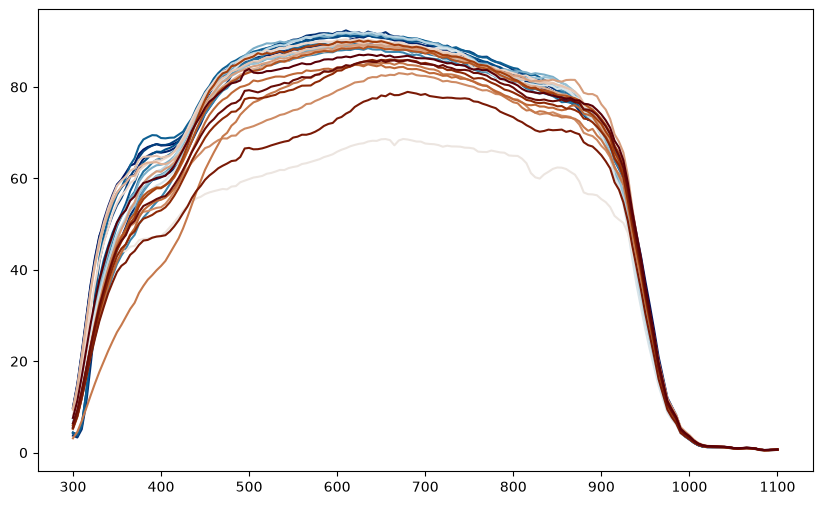

In [42]:
# plot lambda vs EQE in df
# get the headers that contain EQE and save to a list

headers = [[h] for h in df.columns if h[1] == "EQE (%)"]

cmap=cmc.vik(np.linspace(0, 1, len(headers)))
fig,ax = plt.subplots(figsize=(10,6))
for i, h in enumerate(headers):
    
    ax.plot(df.index, df[h], label=h, color=cmap[i])
    



In [29]:
df.columns.values[1][0]

'G1-3'

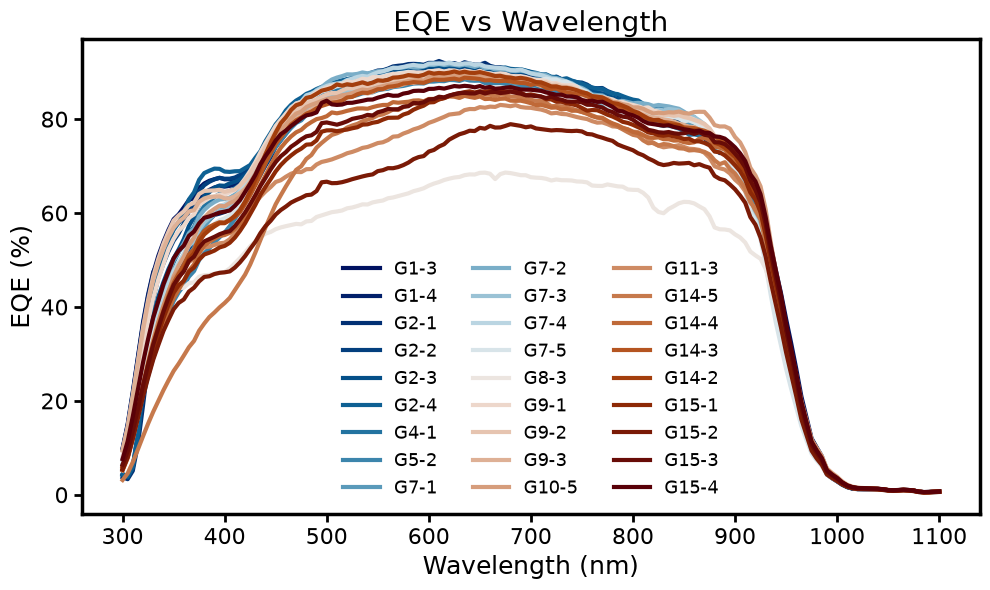

In [43]:
fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(df.columns.get_level_values(0).unique()):
    ax.plot(df.index, df[(name, "EQE (%)")], label=name, linewidth=3, color=cmap[i])

ax.set_xlabel("Wavelength (nm)", fontsize=18)
ax.set_ylabel("EQE (%)", fontsize=18)
ax.tick_params(axis="both", labelsize=16, width=2, length=6)
for spine in ax.spines.values():
    spine.set_linewidth(2.5)
ax.legend(fontsize=13, ncol=3, frameon=False)
plt.title("EQE vs Wavelength", fontsize=20)
plt.tight_layout()
plt.show()
